Câu 1 (Ý a): Đọc dữ liệu groceries.csv, chuyển đổi One-Hot Encoding và chạy thuật toán Apriori với các mức min_sup

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import time
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori

# 1. Đọc dữ liệu từng giao dịch từ file groceries.csv
transactions = []
with open('groceries.csv', 'r', encoding='utf-8') as f:
    for line in f:
        items = [item.strip() for item in line.strip().split(',') if item.strip()]
        if items:
            transactions.append(items)

print("Tổng số giao dịch:", len(transactions))

# 2. Chuyển đổi dữ liệu về dạng One-Hot Encoding bằng TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_groceries = pd.DataFrame(te_ary, columns=te.columns_)
print("Kích thước ma trận One-Hot Encoding:", df_groceries.shape)

# 3. Chạy Apriori qua các mức min_sup và ghi nhận thời gian xử lý
min_sups = [0.01, 0.02, 0.03, 0.05, 0.08, 0.1]
apriori_times = []
apriori_counts = []

for sup in min_sups:
    start_time = time.time()
    freq_items = apriori(df_groceries, min_support=sup, use_colnames=True)
    elapsed = time.time() - start_time

    apriori_times.append(elapsed)
    apriori_counts.append(len(freq_items))
    print(f"Apriori | min_sup = {sup:.2f} | Số tập phổ biến: {len(freq_items):4d} | Thời gian: {elapsed:.4f} giây")

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039
Tổng số giao dịch: 9835
Kích thước ma trận One-Hot Encoding: (9835, 169)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori | min_sup = 0.01 | Số tập phổ biến:  333 | Thời gian: 0.8263 giây


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Apriori | min_sup = 0.02 | Số tập phổ biến:  122 | Thời gian: 0.2355 giây
Apriori | min_sup = 0.03 | Số tập phổ biến:   63 | Thời gian: 0.0973 giây
Apriori | min_sup = 0.05 | Số tập phổ biến:   31 | Thời gian: 0.0664 giây
Apriori | min_sup = 0.08 | Số tập phổ biến:   13 | Thời gian: 0.0256 giây
Apriori | min_sup = 0.10 | Số tập phổ biến:    8 | Thời gian: 0.0149 giây


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Câu 2 (Ý b): Chạy thuật toán FP-Growth trên cùng các mức min_sup và ghi nhận thời gian

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import time
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth

transactions = []
with open('groceries.csv', 'r', encoding='utf-8') as f:
    for line in f:
        items = [item.strip() for item in line.strip().split(',') if item.strip()]
        if items:
            transactions.append(items)

te = TransactionEncoder()
df_groceries = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

# Chạy FP-Growth qua các mức min_sup và ghi nhận thời gian xử lý
min_sups = [0.01, 0.02, 0.03, 0.05, 0.08, 0.1]
fpgrowth_times = []
fpgrowth_counts = []

for sup in min_sups:
    start_time = time.time()
    freq_items = fpgrowth(df_groceries, min_support=sup, use_colnames=True)
    elapsed = time.time() - start_time

    fpgrowth_times.append(elapsed)
    fpgrowth_counts.append(len(freq_items))
    print(f"FP-Growth | min_sup = {sup:.2f} | Số tập phổ biến: {len(freq_items):4d} | Thời gian: {elapsed:.4f} giây")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth | min_sup = 0.01 | Số tập phổ biến:  333 | Thời gian: 11.0207 giây


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth | min_sup = 0.02 | Số tập phổ biến:  122 | Thời gian: 2.0672 giây


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth | min_sup = 0.03 | Số tập phổ biến:   63 | Thời gian: 0.7057 giây


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth | min_sup = 0.05 | Số tập phổ biến:   31 | Thời gian: 0.2240 giây
FP-Growth | min_sup = 0.08 | Số tập phổ biến:   13 | Thời gian: 0.0910 giây
FP-Growth | min_sup = 0.10 | Số tập phổ biến:    8 | Thời gian: 0.0874 giây


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Câu 3 (Ý c): Vẽ biểu đồ so sánh thời gian xử lý của Apriori và FP-Growth

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Họ tên: Đàm Hoàng Lam - MSSV: 6451071039


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,min_sup,Apriori_Time (s),FP_Growth_Time (s)
0,0.01,0.354601,9.584078
1,0.02,0.115436,2.167959
2,0.03,0.061025,1.035993
3,0.05,0.031607,0.398751
4,0.08,0.009623,0.139589
5,0.10,0.007637,0.139975


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

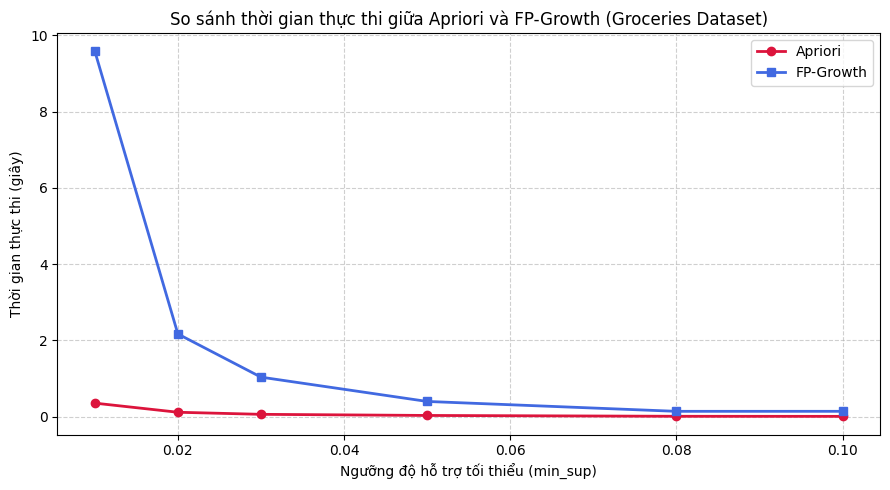

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
print("Họ tên: Đàm Hoàng Lam - MSSV: 6451071039")

import time
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

transactions = []
with open('groceries.csv', 'r', encoding='utf-8') as f:
    for line in f:
        items = [item.strip() for item in line.strip().split(',') if item.strip()]
        if items:
            transactions.append(items)

te = TransactionEncoder()
df_groceries = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)

min_sups = [0.01, 0.02, 0.03, 0.05, 0.08, 0.1]
apriori_times = []
fpgrowth_times = []

for sup in min_sups:
    t0 = time.time()
    apriori(df_groceries, min_support=sup, use_colnames=True)
    apriori_times.append(time.time() - t0)

    t0 = time.time()
    fpgrowth(df_groceries, min_support=sup, use_colnames=True)
    fpgrowth_times.append(time.time() - t0)

# Tạo bảng tổng hợp so sánh
df_compare = pd.DataFrame({
    'min_sup': min_sups,
    'Apriori_Time (s)': apriori_times,
    'FP_Growth_Time (s)': fpgrowth_times
})
display(df_compare)

# Vẽ đồ thị đường so sánh thời gian thực thi
plt.figure(figsize=(9, 5))
plt.plot(min_sups, apriori_times, marker='o', linewidth=2, color='crimson', label='Apriori')
plt.plot(min_sups, fpgrowth_times, marker='s', linewidth=2, color='royalblue', label='FP-Growth')
plt.title('So sánh thời gian thực thi giữa Apriori và FP-Growth (Groceries Dataset)')
plt.xlabel('Ngưỡng độ hỗ trợ tối thiểu (min_sup)')
plt.ylabel('Thời gian thực thi (giây)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()